# 05 · The AI loan officer vs reality

**What this notebook does, in plain words**

Notebook 04 asked Gemini to score 40 real applications, each in 14 versions that differ only by job title, twice (`main_1` and `main_2`). Notebook 03 measured how borrowers with each title **really** repaid compared with their grade. Here we put the two side by side and run the tests fixed in `PREREGISTRATION.md`:

1. How much does each job title move the AI's estimate? (with 95% intervals)
2. Is that movement bigger than the AI's own run-to-run noise?
3. Do titles matter at all? (permutation test)
4. The pre-registered hypothesis: does the AI rate high-status titles safer than modest ones, the reverse of reality?
5. Across the 12 titles, does the AI's ranking match reality's?
6. Which single titles can we make claims about?
7. Sanity check: does the AI react sensibly to FICO and debt?

Only `main_1` and `main_2` are used. Both pilot runs are excluded.

## Setup and data

Loads both runs' scores and the real gaps from notebook 03. Every random step uses one fixed seed, so rerunning gives identical numbers.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

SEED = 2015
N_BOOT = 2_000
N_PERM = 5_000

PREREGISTERED = [
    "software engineer", "police officer", "executive assistant", "attorney", "teacher",
    "registered nurse", "mechanic", "president", "general manager", "owner", "truck driver", "server",
]
EXTRAS = ["(blank)", "employee"]
CONDITIONS = PREREGISTERED + EXTRAS
HIGH_STATUS = ["owner", "general manager", "president"]
MODEST = ["teacher", "police officer", "executive assistant"]

scores = pd.read_csv("outputs/ai_scores.csv")
real = pd.read_csv("outputs/real_gaps.csv", index_col="condition")
base = pd.read_csv("outputs/base_applications.csv")

assert scores[["main_1", "main_2"]].notna().all().all(), "every version should have both scores"
print(f"{scores['app_id'].nunique()} applications x {scores['condition'].nunique()} conditions = {len(scores)} versions, 2 runs each")

40 applications x 14 conditions = 560 versions, 2 runs each


## Step 1 · Each title's effect on the AI

For every version we average its two scores (`main_1` and `main_2`). Then, **within each application**, we subtract that application's average over all 14 versions. What's left is how far that title pushed the score above or below the application's own average. A safe A-grade applicant and a risky D-grade applicant are each compared only with themselves, so differences between applications cancel out.

A title's **effect** is the average of that number over the 40 applications, in percentage points. Positive means the AI thought this title made the loan *riskier*.

The 95% interval comes from the bootstrap: resample the 40 applications with replacement 2,000 times and recompute. We resample **applications**, not single scores, because the 14 versions of one application are linked.

In [2]:
def centred_matrix(score_column):
    """Rows = applications, columns = conditions. Each row has its own average subtracted."""
    m = scores.pivot(index="app_id", columns="condition", values=score_column)[CONDITIONS]
    return m.sub(m.mean(axis=1), axis=0)

scores["avg"] = scores[["main_1", "main_2"]].mean(axis=1)
M = centred_matrix("avg")                      # 40 x 14
effects = M.mean()

def bootstrap_rows(matrix, statistic, seed=SEED, n=N_BOOT):
    """Resample the rows (applications) n times and return the statistic for each resample."""
    rng = np.random.default_rng(seed)
    values = matrix.to_numpy()
    return np.array([statistic(pd.DataFrame(values[rng.integers(0, len(values), len(values))],
                                            columns=matrix.columns)) for _ in range(n)])

boot_effects = bootstrap_rows(M, lambda m: m.mean().to_numpy())   # 2,000 x 14
ai = pd.DataFrame({
    "ai_effect": effects,
    "ai_low": np.percentile(boot_effects, 2.5, axis=0),
    "ai_high": np.percentile(boot_effects, 97.5, axis=0),
}, index=CONDITIONS)
ai.sort_values("ai_effect").round(2)

,ai_effect,ai_low,ai_high
registered nurse,-0.39,-0.80,0.01
truck driver,-0.32,-0.80,0.12
teacher,-0.22,-0.62,0.15
attorney,-0.18,-0.58,0.24
employee,-0.10,-0.51,0.37
server,-0.06,-0.54,0.48
mechanic,-0.04,-0.40,0.33
software engineer,-0.01,-0.50,0.50
(blank),0.02,-0.40,0.41
police officer,0.03,-0.40,0.48


## Step 2 · Noise check: does each title's effect repeat?

The same calculation, done separately on `main_1` and on `main_2`. The two runs used the same versions in different batches, so any difference is noise: the AI's own randomness plus which other applicants shared the batch. If a title's effect were mostly noise, the two runs would disagree.

In [3]:
per_run = pd.DataFrame({run: centred_matrix(run).mean() for run in ["main_1", "main_2"]})
per_run["difference"] = per_run["main_2"] - per_run["main_1"]

print(f"Average absolute difference between runs: {per_run['difference'].abs().mean():.2f} points per title")
print(f"Largest difference: {per_run['difference'].abs().max():.2f} points ({per_run['difference'].abs().idxmax()})")
print(f"Correlation of the 14 title effects between runs: {per_run['main_1'].corr(per_run['main_2']):.3f}")
print(f"Spread of the title effects themselves (standard deviation): {effects.std():.2f} points")
per_run.reindex(ai.sort_values("ai_effect").index).round(2)

Average absolute difference between runs: 0.27 points per title
Largest difference: 0.73 points (mechanic)
Correlation of the 14 title effects between runs: 0.523
Spread of the title effects themselves (standard deviation): 0.30 points


,main_1,main_2,difference
registered nurse,-0.19,-0.59,-0.40
truck driver,-0.49,-0.15,0.34
teacher,-0.10,-0.34,-0.24
attorney,-0.28,-0.08,0.21
employee,-0.20,0.01,0.21
server,-0.15,0.04,0.18
mechanic,-0.40,0.32,0.73
software engineer,-0.10,0.07,0.18
(blank),-0.02,0.06,0.08
police officer,0.25,-0.19,-0.44


## Step 3 · Do job titles matter to the AI at all?

The **permutation test** asks: could a spread of title effects this large happen by pure chance?

We measure the spread as the standard deviation of the 14 title effects. Then we break any real link between title and score by **shuffling the 14 title labels within each application**, recompute the spread, and repeat 5,000 times. That gives the spread we'd see if titles meant nothing. The p-value is the share of shuffles with a spread at least as big as the real one.

In [4]:
def spread(matrix_values):
    return matrix_values.mean(axis=0).std(ddof=1)

rng = np.random.default_rng(SEED)
values = M.to_numpy()
observed_spread = spread(values)
shuffled_spreads = np.array([spread(rng.permuted(values, axis=1)) for _ in range(N_PERM)])
perm_p = (1 + (shuffled_spreads >= observed_spread).sum()) / (1 + N_PERM)

print(f"Real spread of title effects: {observed_spread:.2f} points")
print(f"Spread when titles are shuffled: typically {np.median(shuffled_spreads):.2f}, "
      f"95% of shuffles below {np.percentile(shuffled_spreads, 95):.2f}")
print(f"Permutation p-value: {perm_p:.4f}  (smallest possible with 5,000 shuffles: {1 / (1 + N_PERM):.4f})")

Real spread of title effects: 0.30 points
Spread when titles are shuffled: typically 0.23, 95% of shuffles below 0.30
Permutation p-value: 0.0666  (smallest possible with 5,000 shuffles: 0.0002)


## Step 4 · The pre-registered hypothesis

**Contrast** = (average effect of owner, general manager, president) − (average effect of teacher, police officer, executive assistant).

- **Reality:** positive (the high-status titles really defaulted *more* than their grade predicted).
- **Hypothesis:** the AI's contrast is **negative**, meaning it rates the high-status titles as safer.

**AI interval:** bootstrap over applications, as above.

**Reality interval:** the six titles' loans are separate groups of borrowers, so their uncertainties add up. Each title's standard error is read from its 95% interval in notebook 03 (width ÷ 3.92) and combined.

**Note on president:** president's real gap flipped sign between loans issued before 2015 (in practice late 2013–2014) and 2015 (notebook 03). The pre-registered test includes it, so that is the main result. Dropping president is a **post-hoc check**, decided after seeing the real data but before seeing any AI results.

In [5]:
def ai_contrast(matrix, high, low):
    return matrix[high].mean(axis=0).mean() - matrix[low].mean(axis=0).mean()

def real_contrast(high, low):
    se = (real["ci_high"] - real["ci_low"]) / (2 * 1.96)
    value = real.loc[high, "real_gap_pp"].mean() - real.loc[low, "real_gap_pp"].mean()
    combined_se = np.sqrt((se[high] ** 2).sum() / len(high) ** 2 + (se[low] ** 2).sum() / len(low) ** 2)
    return value, value - 1.96 * combined_se, value + 1.96 * combined_se

rows = []
for label, high in [("Pre-registered (owner, general manager, president)", HIGH_STATUS),
                    ("Post-hoc check: without president", ["owner", "general manager"])]:
    boot = bootstrap_rows(M, lambda m: ai_contrast(m, high, MODEST))
    a = ai_contrast(M, high, MODEST)
    r, r_lo, r_hi = real_contrast(high, MODEST)
    rows.append({"test": label, "ai_contrast": a, "ai_low": np.percentile(boot, 2.5), "ai_high": np.percentile(boot, 97.5),
                 "real_contrast": r, "real_low": r_lo, "real_high": r_hi})
hypothesis = pd.DataFrame(rows).set_index("test")
hypothesis.round(2)

,ai_contrast,ai_low,ai_high,real_contrast,real_low,real_high
test,,,,,,
"Pre-registered (owner, general manager, president)",0.45,0.14,0.80,4.87,3.87,5.88
Post-hoc check: without president,0.25,-0.11,0.62,5.70,4.62,6.78


## Step 5 · Does the AI's ranking of titles match reality?

Across the 12 pre-registered titles (blank and `employee` are left out: blank isn't a job title and `employee` has only 28 real loans):

- **Spearman rank correlation:** do the titles the AI calls riskiest match the ones that really were riskiest? +1 is the same order, 0 no relation, −1 the reverse order.
- **Slope:** for each extra point of real gap, how many points does the AI's effect move? 1 means the right size. Above 1 means the AI exaggerates; between 0 and 1, it under-reacts; below 0, it gets the direction wrong.

**Two kinds of uncertainty, two intervals:**
- *Which titles:* resample the 12 titles with replacement. **With only 12 points these intervals are wide**, and that is honest.
- *Which applications:* resample the 40 applications and recompute the AI's effects, keeping the real gaps fixed.

**Zero points differ.** The AI's zero is the application's own average over its 14 versions; reality's zero is the grade's prediction. Neither the rank correlation nor the slope depends on where zero sits, so this comparison is fair.

In [6]:
x_real = real.loc[PREREGISTERED, "real_gap_pp"].to_numpy()
y_ai = effects[PREREGISTERED].to_numpy()

def rho_and_slope(x, y):
    if len(np.unique(x)) < 3:
        return np.nan, np.nan
    return stats.spearmanr(x, y).statistic, np.polyfit(x, y, 1)[0]

rho, slope = rho_and_slope(x_real, y_ai)
rng = np.random.default_rng(SEED)
by_title = np.array([rho_and_slope(x_real[i], y_ai[i])
                     for i in (rng.integers(0, 12, 12) for _ in range(N_BOOT))])
by_app = np.array([rho_and_slope(x_real, row[[CONDITIONS.index(t) for t in PREREGISTERED]])
                   for row in boot_effects])

def interval(a):
    return f"{np.nanpercentile(a, 2.5):+.2f} to {np.nanpercentile(a, 97.5):+.2f}"

spearman_p = stats.spearmanr(x_real, y_ai).pvalue
print(f"Spearman rank correlation: {rho:+.2f}   (p = {spearman_p:.3f})")
print(f"   95% interval, resampling titles:       {interval(by_title[:, 0])}")
print(f"   95% interval, resampling applications: {interval(by_app[:, 0])}")
print(f"Slope (AI points per real point): {slope:+.2f}")
print(f"   95% interval, resampling titles:       {interval(by_title[:, 1])}")
print(f"   95% interval, resampling applications: {interval(by_app[:, 1])}")
print("With only 12 titles these intervals are wide. Read them as a range of plausible values, not a precise estimate.")

Spearman rank correlation: +0.00   (p = 1.000)
   95% interval, resampling titles:       -0.57 to +0.63
   95% interval, resampling applications: -0.39 to +0.54
Slope (AI points per real point): +0.01
   95% interval, resampling titles:       -0.03 to +0.07
   95% interval, resampling applications: -0.04 to +0.05
With only 12 titles these intervals are wide. Read them as a range of plausible values, not a precise estimate.


## Step 6 · Which single titles can we make claims about?

For each title we test whether the AI's effect differs from zero, using a **one-sample t-test** on its 40 application-level numbers ("is the average of these 40 numbers different from zero?").

Testing 12 titles at once means one could look significant by luck, so a title only counts if **p < 0.05 ÷ 12 ≈ 0.0042** (the Bonferroni rule, fixed in the pre-registration).

We also check whether the AI's effect points **the same way as reality**. Where reality's own 95% interval crosses zero (mechanic, president), reality has no clear direction, so we mark it "unclear" rather than counting a match or a miss.

In [7]:
BONFERRONI = 0.05 / len(PREREGISTERED)
claims = ai.loc[CONDITIONS].copy()
claims["p_value"] = [stats.ttest_1samp(M[t], 0).pvalue for t in CONDITIONS]
claims["significant"] = claims["p_value"] < BONFERRONI
claims["real_gap"] = real.loc[CONDITIONS, "real_gap_pp"]
claims["real_low"] = real.loc[CONDITIONS, "ci_low"]
claims["real_high"] = real.loc[CONDITIONS, "ci_high"]
reality_clear = (claims["real_low"] > 0) | (claims["real_high"] < 0)
same_way = np.sign(claims["ai_effect"]) == np.sign(claims["real_gap"])
claims["same_direction"] = np.where(~reality_clear, "unclear", np.where(same_way, "yes", "NO"))
claims["in_comparison"] = claims.index.isin(PREREGISTERED)   # blank and employee: shown, not tested

pre = claims.loc[PREREGISTERED]
print(f"Bonferroni threshold: p < {BONFERRONI:.4f}")
print(f"Titles with a significant AI effect: {int(pre['significant'].sum())} of 12")
print(f"Of those, same direction as reality: {int(((pre['significant']) & (pre['same_direction'] == 'yes')).sum())}, "
      f"opposite: {int(((pre['significant']) & (pre['same_direction'] == 'NO')).sum())}, "
      f"reality unclear: {int(((pre['significant']) & (pre['same_direction'] == 'unclear')).sum())}")
claims.sort_values("real_gap")[["in_comparison", "ai_effect", "ai_low", "ai_high", "p_value", "significant",
                                "real_gap", "real_low", "real_high", "same_direction"]].round(4)

Bonferroni threshold: p < 0.0042
Titles with a significant AI effect: 1 of 12
Of those, same direction as reality: 0, opposite: 0, reality unclear: 1


,in_comparison,ai_effect,ai_low,ai_high,p_value,significant,real_gap,real_low,real_high,same_direction
software engineer,True,-0.0143,-0.4968,0.4964,0.9556,False,-5.82,-7.19,-4.48,yes
police officer,True,0.0295,-0.3997,0.4777,0.8993,False,-3.65,-5.00,-2.23,NO
executive assistant,True,0.0470,-0.3893,0.4717,0.8330,False,-3.38,-4.97,-1.73,NO
attorney,True,-0.1793,-0.5766,0.2353,0.4055,False,-3.15,-4.37,-1.93,yes
teacher,True,-0.2168,-0.6173,0.1509,0.2781,False,-2.15,-2.72,-1.55,yes
registered nurse,True,-0.3905,-0.8008,0.0085,0.0704,False,-0.99,-1.80,-0.14,yes
mechanic,True,-0.0393,-0.4024,0.3307,0.8403,False,-0.20,-2.10,1.76,unclear
president,True,0.8120,0.3809,1.2628,0.0010,True,0.16,-1.11,1.50,unclear
general manager,True,0.0520,-0.3682,0.4770,0.8155,False,2.45,1.20,3.82,yes
owner,True,0.3470,-0.0141,0.7191,0.0730,False,2.83,1.94,3.75,yes


## Step 7 · Sanity check: does the AI react to the things that should matter?

If the AI is a sensible loan officer, applications with **lower FICO** and **higher debt-to-income** should get higher risk scores. Each application's score here is its average over all 28 scores (14 versions × 2 runs). With 40 applications, correlations stronger than about ±0.31 are unlikely to be chance (p < 0.05).

We also show the average score by LendingClub grade, which the AI never saw.

In [8]:
per_app = scores.groupby("app_id")["avg"].mean().rename("ai_avg_score").to_frame()
per_app = per_app.join(base.set_index("app_id")[["grade", "fico", "dti", "annual_inc", "default"]])

for column, should_be in [("fico", "negative"), ("dti", "positive")]:
    r, p = stats.pearsonr(per_app["ai_avg_score"], per_app[column])
    rs = stats.spearmanr(per_app["ai_avg_score"], per_app[column]).statistic
    print(f"AI score vs {column.upper():4s}: correlation {r:+.2f} (p = {p:.4f}), rank correlation {rs:+.2f}  [should be {should_be}]")

per_app.groupby("grade").agg(apps=("ai_avg_score", "size"), ai_avg_score=("ai_avg_score", "mean"),
                             mean_fico=("fico", "mean"), mean_dti=("dti", "mean")).round(1)

AI score vs FICO: correlation -0.90 (p = 0.0000), rank correlation -0.84  [should be negative]
AI score vs DTI : correlation -0.13 (p = 0.4393), rank correlation -0.21  [should be positive]


,apps,ai_avg_score,mean_fico,mean_dti
grade,,,,
A,10,12.2,727.5,19.9
B,10,17.8,685.5,17.3
C,10,18.3,674.0,20.0
D,10,17.5,689.5,21.6


## Chart A · Each title: the AI vs reality

One row per title, sorted by the real gap. **Blue** = how much the title moves the AI's estimate. **Orange** = how much borrowers with that title really defaulted above or below their grade. Lines are 95% intervals. If the AI matched reality, the two dots on each row would sit together.

Blank and `employee` sit above the line in gray because they're left out of the comparison. `employee`'s real gap isn't drawn (only 28 loans; its interval runs from −4 to +30).

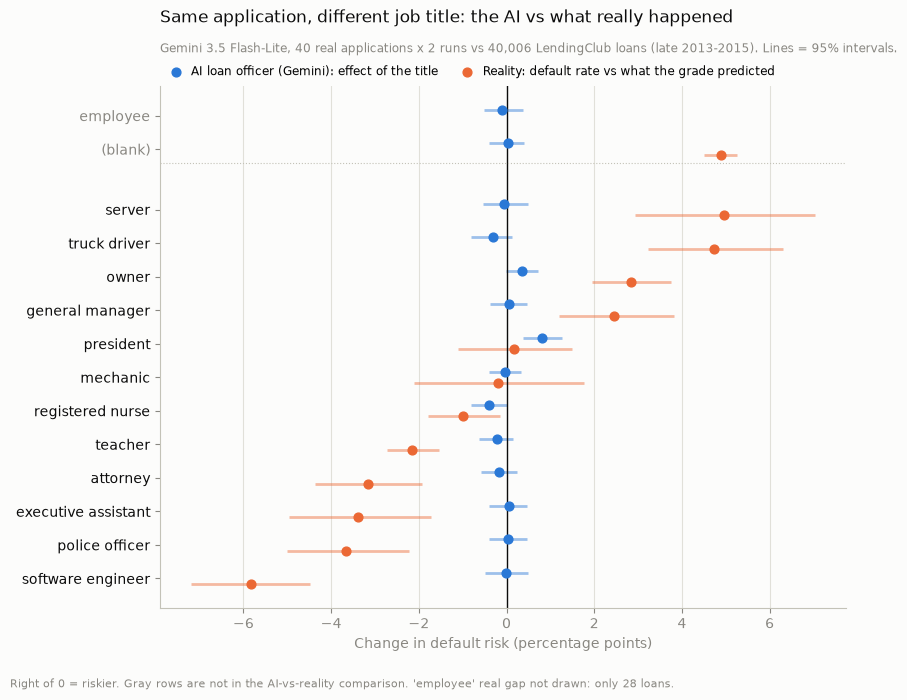

In [9]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"

def style(ax):
    ax.set_facecolor("#fcfcfb")
    ax.set_axisbelow(True)
    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)
    for side in ["bottom", "left"]:
        ax.spines[side].set_color("#c3c2b7")
    ax.tick_params(colors=MUTED)

order = list(real.loc[PREREGISTERED].sort_values("real_gap_pp").index) + EXTRAS
y = np.array(list(range(12)) + [12.8, 13.8])
OFFSET = 0.17

fig, ax = plt.subplots(figsize=(9, 7), facecolor="#fcfcfb")
style(ax)
for yi, t in zip(y, order):
    ax.hlines(yi + OFFSET, ai.loc[t, "ai_low"], ai.loc[t, "ai_high"], color=BLUE, linewidth=2, alpha=0.45)
    ax.scatter(ai.loc[t, "ai_effect"], yi + OFFSET, color=BLUE, s=40, zorder=3,
               label="AI loan officer (Gemini): effect of the title" if t == order[0] else None)
    if t != "employee":
        ax.hlines(yi - OFFSET, real.loc[t, "ci_low"], real.loc[t, "ci_high"], color=ORANGE, linewidth=2, alpha=0.45)
        ax.scatter(real.loc[t, "real_gap_pp"], yi - OFFSET, color=ORANGE, s=40, zorder=3,
                   label="Reality: default rate vs what the grade predicted" if t == order[0] else None)
ax.axvline(0, color=INK, linewidth=1)
ax.axhline(12.4, color="#c3c2b7", linewidth=0.8, linestyle=":")
ax.set_yticks(y, order)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_xlabel("Change in default risk (percentage points)", color=MUTED)
ax.set_title("Same application, different job title: the AI vs what really happened", loc="left", color=INK, fontsize=12, pad=46)
n_title_loans = int(real.loc[PREREGISTERED, "loans"].sum())
ax.text(0, 1.065, f"Gemini 3.5 Flash-Lite, 40 real applications x 2 runs vs {n_title_loans:,} LendingClub loans (late 2013-2015). Lines = 95% intervals.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(-0.01, 0.995), ncol=2, fontsize=8.5,
          handletextpad=0.3, columnspacing=1.5)
# Colour the labels after style() has set every tick gray
for label, t in zip(ax.get_yticklabels(), order):
    label.set_color(MUTED if t in EXTRAS else INK)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.text(0.01, 0.01, "Right of 0 = riskier. Gray rows are not in the AI-vs-reality comparison. "
         "'employee' real gap not drawn: only 28 loans.", color=MUTED, fontsize=8)
Path("outputs").mkdir(exist_ok=True)
fig.savefig("outputs/ai_vs_reality.png", dpi=200)
plt.show()

## Chart B · Does the AI's view line up with reality?

Each dot is one of the 12 titles: across is the real gap, up is the AI's effect. The **dashed diagonal** is where a perfectly calibrated AI would put every title. Dots on a flat line would mean the AI ignores titles. Dots sloping the other way would mean it gets them backwards.

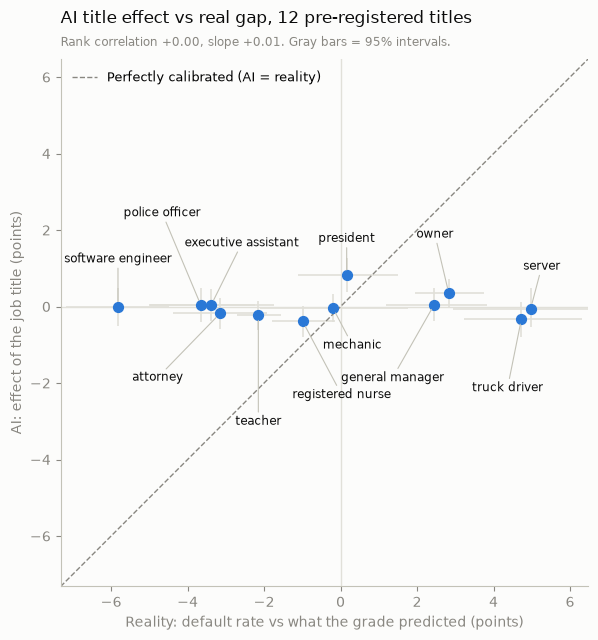

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 6.5), facecolor="#fcfcfb")
style(ax)
xs, ys = real.loc[PREREGISTERED, "real_gap_pp"], effects[PREREGISTERED]
ax.errorbar(xs, ys, yerr=[ys - ai.loc[PREREGISTERED, "ai_low"], ai.loc[PREREGISTERED, "ai_high"] - ys],
            xerr=[xs - real.loc[PREREGISTERED, "ci_low"], real.loc[PREREGISTERED, "ci_high"] - xs],
            fmt="none", ecolor=GRID, elinewidth=1.2, zorder=1)
ax.scatter(xs, ys, color=BLUE, s=50, zorder=3)
low, high = min(xs.min(), ys.min()) - 1.5, max(xs.max(), ys.max()) + 1.5
ax.plot([low, high], [low, high], linestyle="--", color=MUTED, linewidth=1, label="Perfectly calibrated (AI = reality)")
ax.axhline(0, color=GRID, linewidth=1, zorder=0)
ax.axvline(0, color=GRID, linewidth=1, zorder=0)
# Hand-placed labels (in points from the dot) so none overlap; a thin line links each label to its dot
LABEL_OFFSETS = {
    "software engineer": (0, 30), "police officer": (-28, 62), "executive assistant": (22, 40),
    "attorney": (-45, -42), "teacher": (0, -72), "registered nurse": (28, -48),
    "mechanic": (14, -22), "president": (0, 22), "general manager": (-30, -48),
    "owner": (-10, 38), "truck driver": (-10, -45), "server": (8, 26),
}
for t in PREREGISTERED:
    dx, dy = LABEL_OFFSETS.get(t, (6, 4))
    ax.annotate(t, (xs[t], ys[t]), xytext=(dx, dy), textcoords="offset points", fontsize=8.5, color=INK,
                ha="center", va="bottom" if dy > 0 else "top",
                arrowprops=dict(arrowstyle="-", color="#c3c2b7", linewidth=0.8, shrinkA=0, shrinkB=4))
ax.set_xlim(low, high)
ax.set_ylim(low, high)
ax.set_aspect("equal")
ax.set_xlabel("Reality: default rate vs what the grade predicted (points)", color=MUTED)
ax.set_ylabel("AI: effect of the job title (points)", color=MUTED)
ax.set_title("AI title effect vs real gap, 12 pre-registered titles", loc="left", color=INK, fontsize=12, pad=26)
ax.text(0, 1.025, f"Rank correlation {rho:+.2f}, slope {slope:+.2f}. Gray bars = 95% intervals.",
        transform=ax.transAxes, color=MUTED, fontsize=8.5)
ax.legend(frameon=False, loc="upper left", fontsize=9)
plt.tight_layout()
fig.savefig("outputs/ai_vs_reality_scatter.png", dpi=200)
plt.show()

## Applying the pre-registered decision rules

The three possible outcomes, as written in `PREREGISTRATION.md` before any AI results:

1. **Ignores titles:** the permutation test finds no title effect beyond repeat-to-repeat noise.
2. **Tracks reality but exaggerates:** positive rank correlation, slope above 1.
3. **Follows prestige against reality:** the high-status titles average safer than the modest ones, and the correlation is weak or negative.

The code checks each rule against the numbers above, and saves the main table to `outputs/ai_vs_reality.csv`.

In [11]:
main = hypothesis.iloc[0]
titles_matter = perm_p < 0.05
rule_1 = not titles_matter
rule_2 = titles_matter and rho > 0 and slope > 1
rule_3 = titles_matter and main["ai_contrast"] < 0 and rho < 0.3

print(f"Titles matter (permutation p < 0.05)?      {titles_matter}  (p = {perm_p:.4f})")
print(f"Outcome 1, ignores titles:                 {'SUPPORTED' if rule_1 else 'not supported'}")
print(f"Outcome 2, tracks reality but exaggerates: {'SUPPORTED' if rule_2 else 'not supported'}  (rho {rho:+.2f}, slope {slope:+.2f})")
print(f"Outcome 3, prestige against reality:       {'SUPPORTED' if rule_3 else 'not supported'}  "
      f"(AI contrast {main['ai_contrast']:+.2f}, interval {main['ai_low']:+.2f} to {main['ai_high']:+.2f}; rho {rho:+.2f})")
if not (rule_1 or rule_2 or rule_3):
    print("\nNone of the three pre-registered outcomes fits exactly. Describe what the data shows instead.")

out = claims.loc[CONDITIONS, ["in_comparison", "ai_effect", "ai_low", "ai_high", "p_value", "significant",
                              "real_gap", "real_low", "real_high", "same_direction"]]
out = out.join(per_run[["main_1", "main_2"]].add_prefix("ai_effect_"))
out.round(4).to_csv("outputs/ai_vs_reality.csv")
print("\nSaved outputs/ai_vs_reality.csv, outputs/ai_vs_reality.png, outputs/ai_vs_reality_scatter.png")

Titles matter (permutation p < 0.05)?      False  (p = 0.0666)
Outcome 1, ignores titles:                 SUPPORTED
Outcome 2, tracks reality but exaggerates: not supported  (rho +0.00, slope +0.01)
Outcome 3, prestige against reality:       not supported  (AI contrast +0.45, interval +0.14 to +0.80; rho +0.00)

Saved outputs/ai_vs_reality.csv, outputs/ai_vs_reality.png, outputs/ai_vs_reality_scatter.png


## Robustness: does the result hold with a different wording or a different model?

The pre-registration planned these checks, run in notebook 04 on **the same 560 versions in the same batches as `main_1`**:

- **persona:** same model, but the prompt opens with *"You are an experienced loan officer at a lending company reviewing personal loan applications."*
- **gemma:** the plain prompt on `gemma-4-31b-it`, an open model from a different family. **This check could not be completed.** Google's servers kept failing on Gemma: after three attempts with growing retry waits, batch 10 failed all 5 tries, and the run was dropped as decided in advance. Only 9 of 23 batches (220 of 560 versions) were scored, so each application has only some of its 14 versions, and a title comparison would be unbalanced. Gemma is therefore **left out** below, and the code says so when it runs.

Each remaining version gets exactly the same tests as the main result: title effects with intervals, the permutation test, the pre-registered contrast, and the rank correlation with reality.

**A fair comparison needs one detail.** The main plain result averages two runs (`main_1` and `main_2`), which halves the noise. persona and gemma have one run each. So the table also shows **plain using `main_1` only**: same batches, one run, a like-for-like match for persona and gemma.

In [12]:
robust = pd.read_csv("outputs/ai_scores_robustness.csv")
scores = scores.drop(columns=[c for c in ["persona", "gemma"] if c in scores], errors="ignore").merge(
    robust[["version_id", "persona", "gemma"]], on="version_id", how="left")

VARIANTS = {
    "plain (main_1 + main_2)": "avg",
    "plain (main_1 only)": "main_1",
    "persona": "persona",
    "gemma": "gemma",
}
missing = [name for name, col in VARIANTS.items() if scores[col].isna().any()]
if missing:
    print("Left out because some versions have no score:", missing)
VARIANTS = {name: col for name, col in VARIANTS.items() if name not in missing}

def analyse(column, seed=SEED):
    m = centred_matrix(column)
    eff = m.mean()
    boot = bootstrap_rows(m, lambda x: x.mean().to_numpy(), seed=seed)
    rng = np.random.default_rng(seed)
    vals = m.to_numpy()
    obs = spread(vals)
    p_perm = (1 + sum(spread(rng.permuted(vals, axis=1)) >= obs for _ in range(N_PERM))) / (1 + N_PERM)
    c_boot = bootstrap_rows(m, lambda x: ai_contrast(x, HIGH_STATUS, MODEST), seed=seed)
    y = eff[PREREGISTERED].to_numpy()
    r, s = rho_and_slope(x_real, y)
    rng = np.random.default_rng(seed)
    r_boot = np.array([rho_and_slope(x_real[i], y[i]) for i in (rng.integers(0, 12, 12) for _ in range(N_BOOT))])
    p_title = [stats.ttest_1samp(m[t], 0).pvalue for t in PREREGISTERED]
    per_app_score = scores.groupby("app_id")[column].mean()
    fico = base.set_index("app_id")["fico"].reindex(per_app_score.index)
    summary = {
        "mean_score": scores[column].mean(),
        "title_spread": eff.std(ddof=1),
        "largest_effect": eff.abs().max(),
        "largest_effect_title": eff.abs().idxmax(),
        "permutation_p": p_perm,
        "contrast": ai_contrast(m, HIGH_STATUS, MODEST),
        "contrast_low": np.percentile(c_boot, 2.5), "contrast_high": np.percentile(c_boot, 97.5),
        "rank_corr": r, "rank_low": np.nanpercentile(r_boot[:, 0], 2.5), "rank_high": np.nanpercentile(r_boot[:, 0], 97.5),
        "slope": s,
        "titles_significant": int(sum(p < BONFERRONI for p in p_title)),
        "fico_corr": per_app_score.corr(fico),
    }
    effects_table = pd.DataFrame({"effect": eff, "low": np.percentile(boot, 2.5, axis=0),
                                  "high": np.percentile(boot, 97.5, axis=0)}, index=CONDITIONS)
    return summary, effects_table

results, effect_tables = {}, {}
for name, col in VARIANTS.items():
    results[name], effect_tables[name] = analyse(col)
robustness = pd.DataFrame(results).T
real_c = hypothesis.iloc[0]
print(f"Reality, pre-registered contrast: {real_c['real_contrast']:+.2f} ({real_c['real_low']:+.2f} to {real_c['real_high']:+.2f})")
robustness.round(3)

Left out because some versions have no score: ['gemma']


Reality, pre-registered contrast: +4.87 (+3.87 to +5.88)


,mean_score,title_spread,largest_effect,largest_effect_title,permutation_p,contrast,contrast_low,contrast_high,rank_corr,rank_low,rank_high,slope,titles_significant,fico_corr
plain (main_1 + main_2),16.466786,0.295289,0.811964,president,0.066587,0.450417,0.142073,0.799208,0.0,-0.572073,0.627253,0.005383,1,-0.900992
plain (main_1 only),16.307679,0.366883,0.862321,president,0.212557,0.413333,0.014167,0.847542,-0.13986,-0.699643,0.505376,-0.002915,0,-0.894463
persona,16.55625,0.351362,0.80625,president,0.182563,0.520833,0.058333,0.966667,-0.328671,-0.885315,0.433719,-0.012375,0,-0.881761


## Each title's effect under each version

Effect in points, with its 95% interval in brackets, sorted by the real gap. Read across a row to see whether a title's effect holds when the wording or model changes.

In [13]:
def fmt(row):
    return f"{row['effect']:+.2f} [{row['low']:+.2f}, {row['high']:+.2f}]"

side_by_side = pd.DataFrame({name: tab.apply(fmt, axis=1) for name, tab in effect_tables.items()})
side_by_side.insert(0, "real gap", real.loc[CONDITIONS, "real_gap_pp"].map("{:+.2f}".format))
side_by_side.loc[order[::-1]]

,real gap,plain (main_1 + main_2),plain (main_1 only),persona
employee,+13.22,"-0.10 [-0.51, +0.37]","-0.20 [-0.78, +0.49]","-0.33 [-0.87, +0.20]"
(blank),+4.89,"+0.02 [-0.40, +0.41]","-0.02 [-0.63, +0.60]","-0.02 [-0.56, +0.47]"
server,+4.97,"-0.06 [-0.54, +0.48]","-0.15 [-0.80, +0.55]","-0.36 [-0.82, +0.14]"
truck driver,+4.73,"-0.32 [-0.80, +0.12]","-0.49 [-1.03, +0.03]","-0.37 [-0.84, +0.16]"
owner,+2.83,"+0.35 [-0.01, +0.72]","+0.56 [+0.05, +1.10]","+0.59 [+0.10, +1.11]"
general manager,+2.45,"+0.05 [-0.37, +0.48]","+0.12 [-0.42, +0.69]","+0.11 [-0.43, +0.68]"
president,+0.16,"+0.81 [+0.38, +1.26]","+0.86 [+0.32, +1.45]","+0.81 [+0.13, +1.47]"
mechanic,-0.20,"-0.04 [-0.40, +0.33]","-0.40 [-1.03, +0.26]","-0.29 [-0.88, +0.36]"
registered nurse,-0.99,"-0.39 [-0.80, +0.01]","-0.19 [-0.71, +0.37]","-0.07 [-0.58, +0.46]"
teacher,-2.15,"-0.22 [-0.62, +0.15]","-0.10 [-0.64, +0.47]","-0.21 [-0.81, +0.39]"


## Chart C · The three side by side

One panel each for plain (both runs) and persona, on the same scale as Chart A. Gemma would have been a third panel, but its run couldn't be completed (see above). Blue = the AI's title effect with its 95% interval; faint orange = reality. If wording or model changed the story, the blue dots would spread out in one panel and stay bunched at zero in another.

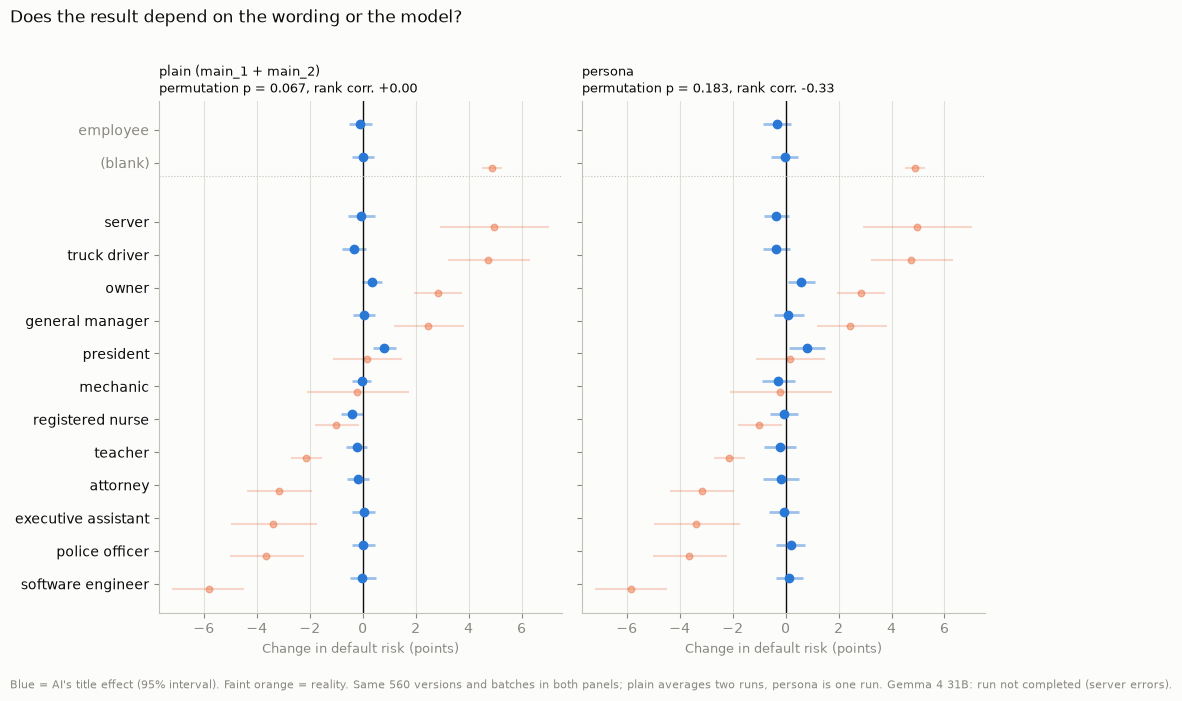

Saved outputs/robustness.png and outputs/robustness.csv


In [14]:
PANELS = [p for p in ["plain (main_1 + main_2)", "persona", "gemma"] if p in effect_tables]
fig, axes = plt.subplots(1, len(PANELS), figsize=(4.2 * len(PANELS) + 1.6, 7), sharey=True, facecolor="#fcfcfb")
axes = np.atleast_1d(axes)
xmin = min(real.loc[PREREGISTERED + ["(blank)"], "ci_low"].min(), min(t["low"].min() for t in effect_tables.values())) - 0.5
xmax = max(real.loc[PREREGISTERED + ["(blank)"], "ci_high"].max(), max(t["high"].max() for t in effect_tables.values())) + 0.5
for ax, name in zip(axes, PANELS):
    style(ax)
    tab = effect_tables[name]
    for yi, t in zip(y, order):
        if t != "employee":
            ax.hlines(yi - OFFSET, real.loc[t, "ci_low"], real.loc[t, "ci_high"], color=ORANGE, linewidth=1.5, alpha=0.25)
            ax.scatter(real.loc[t, "real_gap_pp"], yi - OFFSET, color=ORANGE, s=22, alpha=0.45, zorder=2)
        ax.hlines(yi + OFFSET, tab.loc[t, "low"], tab.loc[t, "high"], color=BLUE, linewidth=2, alpha=0.45)
        ax.scatter(tab.loc[t, "effect"], yi + OFFSET, color=BLUE, s=36, zorder=3)
    ax.axvline(0, color=INK, linewidth=1)
    ax.axhline(12.4, color="#c3c2b7", linewidth=0.8, linestyle=":")
    ax.set_xlim(xmin, xmax)
    ax.grid(axis="x", color=GRID, linewidth=0.8)
    r = results[name]
    ax.set_title(f"{name}\npermutation p = {r['permutation_p']:.3f}, rank corr. {r['rank_corr']:+.2f}",
                 loc="left", color=INK, fontsize=9.5)
    ax.set_xlabel("Change in default risk (points)", color=MUTED, fontsize=9)
axes[0].set_yticks(y, order)
for label, t in zip(axes[0].get_yticklabels(), order):
    label.set_color(MUTED if t in EXTRAS else INK)
fig.suptitle("Does the result depend on the wording or the model?", x=0.01, ha="left", color=INK, fontsize=12)
fig.text(0.01, 0.01, "Blue = AI's title effect (95% interval). Faint orange = reality. Same 560 versions and batches in both panels; "
         "plain averages two runs, persona is one run. Gemma 4 31B: run not completed (server errors).", color=MUTED, fontsize=8)
plt.tight_layout(rect=(0, 0.035, 1, 0.97))
fig.savefig("outputs/robustness.png", dpi=200)
plt.show()

robustness.round(4).to_csv("outputs/robustness.csv")
print("Saved outputs/robustness.png and outputs/robustness.csv")

## Deviations from the pre-registration

Everything that differs from `PREREGISTRATION.md`, listed in one place:

1. **All 12 titles in the main AI-vs-reality comparison.** The pre-registration said the main comparison would use only titles whose real gap keeps its sign between the two periods. That is 10 of 12, because mechanic and president flip. We reported all 12 as the main result. The check below repeats the comparison with only the 10 sign-stable titles.
2. **The third prompt wording was not run.** The pre-registration planned three wordings (plain, "you are a loan officer", and "use financial factors only"). Only the first two were run.
3. **The split-half agreement check was not run.**
4. **Bad replies were retried once, not up to 3 times.** In practice no reply in `main_1`, `main_2` or `persona` failed the checks (counted below), so this made no difference.
5. **The second model was not completed.** Gemma 4 31B was stopped after repeated server errors (notebook 04) and is not analysed.
6. **Batches had 24 or 25 applicants, not exactly 25.** This was needed to balance grades and titles across batches, and it was decided after the pilot, before the main runs.
7. **Post-hoc analyses, labelled as such:** the hypothesis contrast without president. Also, reality's contrast interval was combined from each title's bootstrap interval rather than bootstrapped directly.

In [15]:
STABLE = [t for t in PREREGISTERED if real.loc[t, "same_sign"]]
print(f"Sign-stable titles ({len(STABLE)}): left out: {', '.join(t for t in PREREGISTERED if t not in STABLE)}")
xs10 = real.loc[STABLE, "real_gap_pp"].to_numpy()
ys10 = effects[STABLE].to_numpy()
rho10, slope10 = rho_and_slope(xs10, ys10)
rng = np.random.default_rng(SEED)
boot10 = np.array([rho_and_slope(xs10[i], ys10[i]) for i in (rng.integers(0, len(STABLE), len(STABLE)) for _ in range(N_BOOT))])
print(f"10 sign-stable titles: rank correlation {rho10:+.2f} ({interval(boot10[:, 0])}), slope {slope10:+.2f} ({interval(boot10[:, 1])})")
print(f"All 12 titles (main result): rank correlation {rho:+.2f}, slope {slope:+.2f}")

import json
retries = {r: sum(len(json.loads(p.read_text(encoding="utf-8"))["attempts"]) - 1
                  for p in (Path("outputs/gemini_raw") / r).glob("batch_*.json")) for r in ["main_1", "main_2", "persona"]}
print("Replies that failed the checks and were retried:", retries)

Sign-stable titles (10): left out: mechanic, president


10 sign-stable titles: rank correlation -0.13 (-0.70 to +0.59), slope +0.00 (-0.03 to +0.05)
All 12 titles (main result): rank correlation +0.00, slope +0.01
Replies that failed the checks and were retried: {'main_1': 0, 'main_2': 0, 'persona': 0}


## Summary in plain words

**Which outcome does the data support? Outcome 1: the AI essentially ignores job titles.** The pre-registered hypothesis (the AI follows prestige against reality) is **not** supported.

- **The AI barely moves.** Changing only the job title moves Gemini's estimate by less than 1 point for every title (−0.4 to +0.8). In reality, borrowers with these titles defaulted between 5.8 points less and 5.0 points more than their grade predicted. The permutation test can't separate the AI's title effects from chance (p = 0.067).
- **Size compared with reality:** for each point of real gap, the AI moves about 0.01 points (slope +0.01, interval −0.03 to +0.07). We can say confidently that the AI does **not** react to job titles anywhere near as much as reality would justify.
- **Ranking compared with reality:** the rank correlation is 0.00. With only 12 titles the interval is wide (−0.57 to +0.63), so we can't rule out a weak link in either direction. There is no evidence of one.
- **The prestige hypothesis failed.** The AI rated the high-status titles very slightly *riskier* than the modest ones (+0.45 points, interval +0.14 to +0.80), the same direction as reality but about a tenth of its size (+4.87). Most of that comes from president. Without president (a post-hoc check) the AI's contrast is +0.25, which can't be told apart from zero.
- **One exception: "president".** This is the only title that passes the strict Bonferroni test: +0.81 points, p = 0.001. Reality shows no clear gap for presidents, so this is a small penalty with no support in the data.
- **Noise:** a title's effect differs by 0.27 points on average between the two runs, about as large as the effects themselves. Most title effects are at the noise level.
- **Sanity check:** the AI's scores follow FICO very closely (correlation −0.90), as they should. They don't rise with debt-to-income (−0.13, not significant, wrong sign). The AI seems to lean almost entirely on the credit score.

**Does it hold up?**

- **Different wording: yes.** With the "experienced loan officer" persona prompt, the result is the same. The largest effect is 0.81 points (president again), the permutation p is 0.18, the slope is −0.01, and no title passes Bonferroni. The persona contrast is +0.52 (+0.06 to +0.97): again the same direction as reality, but tiny. President's interval excludes zero under both prompts. Owner's excludes zero under the persona prompt (+0.59, interval +0.10 to +1.11) but not in the main two-run result (+0.35, interval −0.01 to +0.72), so the evidence for an owner penalty is weaker. Both stay under 1 point.
- **Competence check: not detectably worse than the grade (about 0.03 lower).** On 500 random real 2015 loans with no job title, Gemini ranked risk with an AUC of 0.625 (0.553 to 0.696), against 0.657 for LendingClub's sub-grade on the same loans. The difference, −0.03 (−0.105 to +0.035), can't be told apart from zero, but the interval also allows Gemini to be up to about 0.1 worse. So the AI can judge risk from the financial fields; its indifference to job titles isn't because it can't judge risk at all.
- **Different model: not tested.** The planned second model (Gemma 4 31B) could not be run to completion. Google's servers kept returning errors, and the run was dropped after 9 of 23 batches, as decided in advance.

**How confident can we be?** We're confident about the main point. Under two prompt wordings, Gemini 3.5 Flash-Lite does not apply large job-title penalties, and it ignores a real signal worth up to about 5 points. That signal is one our own model in notebook 02 also misses. The result covers one model, 40 applications and 12 titles. Whether other AI models behave the same way is untested.

**What it means.** We found no stereotyping by job title. Whether an AI *should* use job titles is a separate fairness question: they carry real information, but they can also stand in for things like gender or race, which lenders must not use.
